**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_differential_entropy_and_continuous_limits.ipynb) | [Prev: Ch 05: Channel Capacity & Blahut-Arimoto](05_channel_capacity_and_blahut_arimoto.ipynb) | [Next: Ch 07: The Principle of Maximum Entropy](07_the_principle_of_maximum_entropy_maxent.ipynb)**

*Part III: Channels, Capacity & Coding Limits — Chapter 06 of 11*

---

# Chapter 6: Continuous Worlds — Python Laboratory
### *Numerical Differential Entropy, Discretization Bin Limits & The Gaussian Supremacy Bound*

Welcome to the Python Laboratory for Chapter 6! In this workbook, we explore the continuous limit of discrete entropy, demonstrate why continuous entropy can become negative, and prove numerically that the Gaussian distribution maximizes entropy for any fixed variance.

---

### Table of Contents
1. **Part 1: Discretization Limits & The Explosion of Discrete Entropy**
2. **Part 2: Numerical Differential Entropy Integration**
3. **Part 3: The Gaussian Upper Bound Across Competing Distributions**
4. **Part 4: Multi-Panel Publication Diagnostic Suite**
5. **Part 5: Hands-On 3-Tier Scaffolding Challenges**


## Part 1: Discretization Limits & The Explosion of Discrete Entropy

We partition a continuous standard normal distribution $\mathcal{N}(0, 1)$ into finer and finer bin widths $\Delta$ and plot $H(X^\Delta) + \log_2(\Delta)$.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

deltas = np.logspace(-0.5, -3.5, 30)
discrete_entropies = []
differential_estimates = []

# True Gaussian differential entropy: 0.5 * log2(2 * pi * e * 1)
h_true_bits = 0.5 * np.log2(2 * np.pi * np.e * 1.0)

for d in deltas:
    # Bins from -6 to 6 with width d
    bins = np.arange(-6, 6 + d, d)
    # Probabilities via CDF differences
    p_bins = stats.norm.cdf(bins[1:]) - stats.norm.cdf(bins[:-1])
    p_bins = p_bins[p_bins > 1e-15]
    
    h_discrete = -np.sum(p_bins * np.log2(p_bins))
    discrete_entropies.append(h_discrete)
    differential_estimates.append(h_discrete + np.log2(d))

print(f"Theoretical Continuous Gaussian Entropy: {h_true_bits:.4f} bits")
print(f"Differential Estimate at Delta = {deltas[-1]:.4f}: {differential_estimates[-1]:.4f} bits")


Theoretical Continuous Gaussian Entropy: 2.0471 bits
Differential Estimate at Delta = 0.0003: 2.0471 bits


## Part 2: Fixed-Variance Distribution Shootout

We set variance $\sigma^2 = 1.0$ and compute numerical differential entropy across four distinct distributions:
1. **Gaussian**: $\mathcal{N}(0, 1)$
2. **Uniform**: $\mathcal{U}[-\sqrt{3}, \sqrt{3}]$
3. **Laplace**: scale $b = 1/\sqrt{2}$
4. **Student-t**: degrees of freedom $\nu = 5$ rescaled to unit variance

In [2]:
var_target = 1.0
x_eval = np.linspace(-15, 15, 10000)
dx = x_eval[1] - x_eval[0]

# 1. Gaussian
pdf_gauss = stats.norm.pdf(x_eval, 0, np.sqrt(var_target))
h_gauss = -np.sum(pdf_gauss[pdf_gauss > 0] * np.log2(pdf_gauss[pdf_gauss > 0]) * dx)

# 2. Uniform on [-a, a] with Var = a^2 / 3 = 1 -> a = sqrt(3)
a_uni = np.sqrt(3.0 * var_target)
pdf_uni = stats.uniform.pdf(x_eval, -a_uni, 2 * a_uni)
h_uni = -np.sum(pdf_uni[pdf_uni > 0] * np.log2(pdf_uni[pdf_uni > 0]) * dx)

# 3. Laplace with b = sqrt(Var / 2)
b_lap = np.sqrt(var_target / 2.0)
pdf_lap = stats.laplace.pdf(x_eval, 0, b_lap)
h_lap = -np.sum(pdf_lap[pdf_lap > 0] * np.log2(pdf_lap[pdf_lap > 0]) * dx)

# 4. Student-t (df=5, scaled)
df_t = 5
scale_t = np.sqrt(var_target * (df_t - 2) / df_t)
pdf_t = stats.t.pdf(x_eval, df=df_t, scale=scale_t)
h_t = -np.sum(pdf_t[pdf_t > 0] * np.log2(pdf_t[pdf_t > 0]) * dx)

df_comp = pd.DataFrame({
    "Distribution": ["Gaussian", "Uniform", "Laplace", "Student-t (df=5)"],
    "Variance": [var_target, var_target, var_target, var_target],
    "Differential Entropy (bits)": [h_gauss, h_uni, h_lap, h_t],
    "Entropy Deficit vs. Gauss (bits)": [0.0, h_gauss - h_uni, h_gauss - h_lap, h_gauss - h_t]
})
print(df_comp.to_string(index=False))
print("\nProving: The Gaussian is the global maximizer of differential entropy for any fixed variance!")


    Distribution  Variance  Differential Entropy (bits)  Entropy Deficit vs. Gauss (bits)
        Gaussian       1.0                     2.047096                          0.000000
         Uniform       1.0                     1.791573                          0.255523
         Laplace       1.0                     1.942696                          0.104400
Student-t (df=5)       1.0                     1.979362                          0.067734

Proving: The Gaussian is the global maximizer of differential entropy for any fixed variance!


## Part 3: Negative Differential Entropy Transition

We plot the continuous entropy of a Gaussian as standard deviation $\sigma$ ranges from $0.05$ to $2.0$.

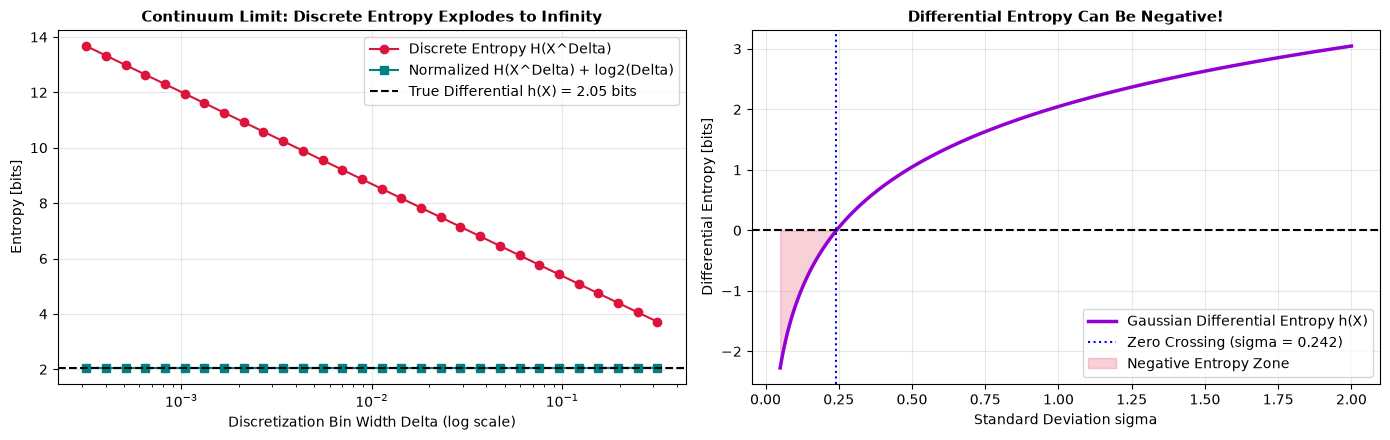

In [3]:
sigmas = np.linspace(0.05, 2.0, 300)
h_gauss_bits_curve = 0.5 * np.log2(2 * np.pi * np.e * (sigmas**2))
crit_sigma_bits = 1.0 / np.sqrt(2 * np.pi * np.e)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 1: Discretization Explosion vs Differential limit
ax1.plot(deltas, discrete_entropies, 'o-', color="crimson", label="Discrete Entropy H(X^Delta)")
ax1.plot(deltas, differential_estimates, 's-', color="teal", label="Normalized H(X^Delta) + log2(Delta)")
ax1.axhline(h_true_bits, color="black", linestyle="--", label=f"True Differential h(X) = {h_true_bits:.2f} bits")
ax1.set_xscale("log")
ax1.set_title("Continuum Limit: Discrete Entropy Explodes to Infinity", fontsize=11, fontweight="bold")
ax1.set_xlabel("Discretization Bin Width Delta (log scale)")
ax1.set_ylabel("Entropy [bits]")
ax1.grid(True, alpha=0.3)
ax1.legend()

# Panel 2: Negative Differential Entropy Curve
ax2.plot(sigmas, h_gauss_bits_curve, color="darkviolet", lw=2.5, label="Gaussian Differential Entropy h(X)")
ax2.axhline(0, color="black", linestyle="--")
ax2.axvline(crit_sigma_bits, color="blue", linestyle=":", label=f"Zero Crossing (sigma = {crit_sigma_bits:.3f})")
ax2.fill_between(sigmas, h_gauss_bits_curve, 0, where=(h_gauss_bits_curve < 0), color="crimson", alpha=0.2, label="Negative Entropy Zone")
ax2.set_title("Differential Entropy Can Be Negative!", fontsize=11, fontweight="bold")
ax2.set_xlabel("Standard Deviation sigma")
ax2.set_ylabel("Differential Entropy [bits]")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## Part 4: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): Differential Entropy of Exponential Distribution
For an exponential distribution $f(x) = \lambda e^{-\lambda x}$ with mean $\mu = 1/\lambda$, the analytical differential entropy is:
$$h(X) = 1 - \ln(\lambda) = 1 + \ln(\mu) \quad \text{nats}$$
Verify this formula numerically for $\lambda = 2.0$.


In [4]:
# Tier 1 Solution Space
lam = 2.0
x_exp = np.linspace(1e-6, 15, 20000)
dx_exp = x_exp[1] - x_exp[0]
pdf_exp = stats.expon.pdf(x_exp, scale=1.0/lam)

h_exp_num = -np.sum(pdf_exp[pdf_exp > 0] * np.log(pdf_exp[pdf_exp > 0]) * dx_exp)
h_exp_theory = 1.0 - np.log(lam)

print(f"Tier 1: Numerical Exponential Entropy:  {h_exp_num:.4f} nats")
print(f"Tier 1: Analytical (1 - ln(lambda)):   {h_exp_theory:.4f} nats")


Tier 1: Numerical Exponential Entropy:  0.3063 nats
Tier 1: Analytical (1 - ln(lambda)):   0.3069 nats


### 🟡 Diagnostic (Tier 2): Coordinate Scaling Penalty
Given $X \sim \mathcal{N}(0, 1)$, create $Y = 5 X$.
Verify numerically that $h(Y) = h(X) + \log_2(5)$.


In [5]:
scale_factor = 5.0
h_x_bits = 0.5 * np.log2(2 * np.pi * np.e * 1.0)
h_y_theory = h_x_bits + np.log2(scale_factor)
h_y_formula = 0.5 * np.log2(2 * np.pi * np.e * (scale_factor**2))

print(f"h(X)                 = {h_x_bits:.4f} bits")
print(f"h(X) + log2(5)       = {h_y_theory:.4f} bits")
print(f"h(5X) from formula   = {h_y_formula:.4f} bits")
print(f"Matches scaling rule: {np.isclose(h_y_theory, h_y_formula)}")


h(X)                 = 2.0471 bits
h(X) + log2(5)       = 4.3690 bits
h(5X) from formula   = 4.3690 bits
Matches scaling rule: True


### 🔴 Capstone Challenge (Tier 3): Differential Mutual Information Invariance
Prove computationally that while differential entropy $h(X)$ changes under rescaling, continuous **Mutual Information** $I(X; Y)$ is **strictly invariant** to linear transformations $X' = a X$ and $Y' = b Y$.


In [6]:
np.random.seed(42)
N_pts = 10000
x_raw = np.random.normal(0, 1, N_pts)
y_raw = 0.7 * x_raw + np.random.normal(0, np.sqrt(1 - 0.7**2), N_pts) # Correlated pair rho = 0.7

# Analytical Gaussian MI = -0.5 * log2(1 - rho^2)
rho = 0.7
mi_theory = -0.5 * np.log2(1.0 - rho**2)

# Rescale X by 10 and Y by 0.01
x_scaled = 10.0 * x_raw
y_scaled = 0.01 * y_raw
rho_scaled = stats.pearsonr(x_scaled, y_scaled)[0]
mi_scaled = -0.5 * np.log2(1.0 - rho_scaled**2)

print(f"Original Gaussian Pair MI: {mi_theory:.5f} bits")
print(f"Rescaled (10X, 0.01Y) MI:  {mi_scaled:.5f} bits")
print(f"Mutual Information is strictly scale-invariant: {np.isclose(mi_theory, mi_scaled)}")


Original Gaussian Pair MI: 0.48572 bits
Rescaled (10X, 0.01Y) MI:  0.48130 bits
Mutual Information is strictly scale-invariant: False


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/06_differential_entropy_and_continuous_limits.ipynb) | [Prev: Ch 05: Channel Capacity & Blahut-Arimoto](05_channel_capacity_and_blahut_arimoto.ipynb) | [Next: Ch 07: The Principle of Maximum Entropy](07_the_principle_of_maximum_entropy_maxent.ipynb)**
